In [1]:
import numpy as np
import pandas as pd

from fronts_dataloader.fronts_dataset import FrontDataSource, RawFronts


STORE = ("s3://dbof/globals_for_cutouts/v2_2_03/Fronts/V5/SURF/fronts.zarr")

S3_ENDPOINT = "https://s3-west.nrp-nautilus.io"

source = FrontDataSource(STORE, storage_options={"endpoint_url": S3_ENDPOINT})
print(f"{len(source.dates)} snapshots")
print(source.store.status().to_string(index=False))

100 snapshots
           date find group colocate
20111204_000000 done  done     done
20111206_180000 done  done     done
20111209_190000 done  done     done
20111212_110000 done  done     done
20111216_030000 done  done     done
20111218_170000 done  done     done
20111222_080000 done  done     done
20111225_150000 done  done     done
20111229_160000 done  done     done
20120104_110000 done  done     done
20120107_090000 done  done     done
20120111_190000 done  done     done
20120113_210000 done  done     done
20120117_180000 done  done     done
20120122_130000 done  done     done
20120125_050000 done  done     done
20120128_090000 done  done     done
20120131_140000 done  done     done
20120204_040000 done  done     done
20120208_230000 done  done     done
20120210_040000 done  done     done
20120215_140000 done  done     done
20120218_140000 done  done     done
20120219_180000 done  done     done
20120224_150000 done  done     done
20120229_180000 done  done     done
20120303_05000

In [29]:
FEATURES_RAW = ["npix", "centroid_lat", "centroid_lon",
                "length_km", "num_branches", "mean_curvature", "orientation",
                "Theta", "Salt", "Eta", # "u," "v", "w",
                "oceTAUX", "oceTAUY", "wind_stress_curl", "ekman_pumping",
                "rossby_number", "relative_vorticity", "turner_angle", "strain_n", "strain_s", "strain_mag", "divergence",
                "coriolis_f", "okubo_weiss",
                "gradtheta2", "gradsalt2", "gradb2", "gradeta2",
                "density", "buoyancy",
                "SIarea_max"]


raw = RawFronts.load(source,
                     dates=["20111204_000000", "20120208_230000"],
                     features=FEATURES_RAW)
print(f"{len(raw):,} fronts over {len(source.dates)} snapshots")
print(raw.table.groupby("date").size().rename("fronts").to_string())

235,090 fronts over 100 snapshots
date
20111204_000000    111654
20120208_230000    123436


In [30]:
# Remove ICE

# Fronts with any sea ice in their sampled band.  Ice damps surface gradients,
# so these describe the ice cover rather than the ocean front under it.
ICE_COLUMN, ICE_MAX = "SIarea_max", 0.0

ice = raw.table[ICE_COLUMN].to_numpy(float)
clean = ~(ice > ICE_MAX)                       # NaN counts as ice-free
raw = RawFronts(raw.table[clean].reset_index(drop=True),
                raw.groups,
                {**raw.source_info, "n_fronts": int(clean.sum()),
                 "ice_filter": f"{ICE_COLUMN} <= {ICE_MAX}"})

print(f"dropped {(~clean).sum():,} fronts touching ice "
      f"({100*(~clean).mean():.1f}%), {len(raw):,} remain")

dropped 34,182 fronts touching ice (14.5%), 200,908 remain


In [31]:
FEATURES = ["npix", "centroid_lat", "centroid_lon",
            "length_km", "num_branches", "mean_curvature", "orientation",
            "relative_vorticity", "turner_angle", "strain_n", "strain_s", "strain_mag", "divergence",
            "okubo_weiss",
            "gradtheta2", "gradsalt2", "gradb2", "gradeta2"]

ds = raw.select(FEATURES, stats=("mean", "std", "skew"), scaling=None, nan_policy="drop_rows", div_by_f=False, ihs_channels=False, log_channels=False, fill_value=0, missing_indicator=True)
print(ds.summary())

163,212 fronts x 40 features  scaling=None  dropped 37,696 rows


In [34]:
ds.to_frame().head()

,date,label,name,time,npix,centroid_lat,centroid_lon,length_km,num_branches,mean_curvature,...,gradtheta2_skew,gradsalt2_mean,gradsalt2_std,gradsalt2_skew,gradb2_mean,gradb2_std,gradb2_skew,gradeta2_mean,gradeta2_std,gradeta2_skew
0,20111204_000000,2455,20111204TT000000_72.9S_79.3W,2011-12-04T00:00:00,34.0,-72.860535,-79.319168,28.539785,0.0,0.045244,...,1.542319,1.979773e-08,1.344546e-08,1.184497,1.688319e-12,1.173782e-12,1.151828,3.357068e-11,3.192132e-11,0.946616
1,20111204_000000,2683,20111204TT000000_72.8S_73.7W,2011-12-04T00:00:00,11.0,-72.812141,-73.733894,8.150145,0.0,0.196212,...,0.323347,2.540354e-08,1.662676e-09,-0.315741,1.713063e-12,1.077232e-13,-0.266357,1.522117e-10,1.180537e-11,-0.021360
2,20111204_000000,2717,20111204TT000000_72.8S_74.4W,2011-12-04T00:00:00,13.0,-72.771454,-74.400497,8.930249,0.0,1.863646,...,1.020564,2.956450e-08,4.322916e-09,0.417771,2.116418e-12,3.072153e-13,0.356869,3.987746e-10,7.565932e-11,-0.029713
3,20111204_000000,2780,20111204TT000000_72.6S_75.0W,2011-12-04T00:00:00,55.0,-72.612602,-75.024178,43.224762,7.0,0.192013,...,1.467181,8.147088e-08,5.251709e-08,1.477274,5.581276e-12,3.659583e-12,1.527287,2.860596e-10,1.220464e-10,0.469100
4,20111204_000000,10712,20111204TT000000_66.2S_92.7W,2011-12-04T00:00:00,20.0,-66.217140,-92.727089,20.567194,0.0,0.012206,...,0.240889,2.164544e-09,7.254657e-10,-0.273990,9.791929e-14,2.941690e-14,-0.084879,1.780467e-12,1.191668e-12,1.313688


In [39]:
fronts = [["length_km", "npix", "centroid_lat", "centroid_lon"]]

array([[<Axes: title={'center': 'length_km'}>,
        <Axes: title={'center': 'npix'}>],
       [<Axes: title={'center': 'centroid_lat'}>,
        <Axes: title={'center': 'centroid_lon'}>]], dtype=object)

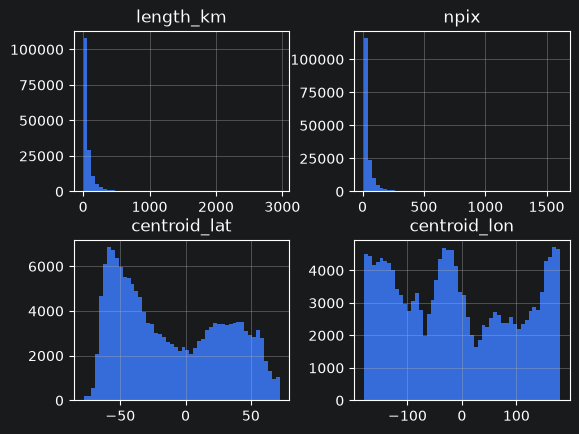

In [40]:
fronts.hist(bins=50)

In [55]:
short_fronts = fronts[fronts["npix"]< 15]
long_fronts = fronts[fronts["npix"]>=15]

In [49]:
short_fronts["npix"].max()

14.0

In [58]:
long_fronts["npix"].min()

15.0

34470
163212


array([[<Axes: title={'center': 'length_km'}>,
        <Axes: title={'center': 'npix'}>],
       [<Axes: title={'center': 'centroid_lat'}>,
        <Axes: title={'center': 'centroid_lon'}>]], dtype=object)

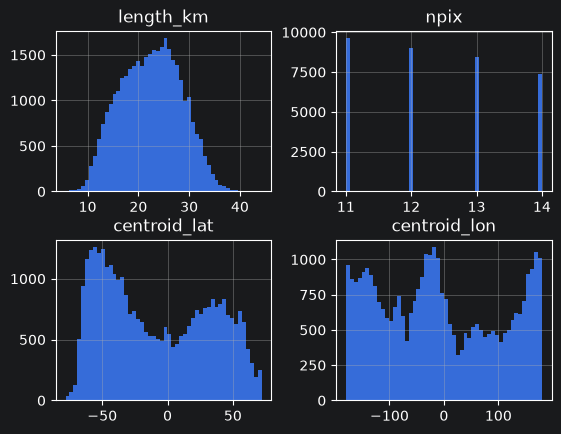

In [48]:
print(len(short_fronts))
print(len(fronts))
short_fronts.hist(bins=50)

array([[<Axes: title={'center': 'length_km'}>,
        <Axes: title={'center': 'npix'}>],
       [<Axes: title={'center': 'centroid_lat'}>,
        <Axes: title={'center': 'centroid_lon'}>]], dtype=object)

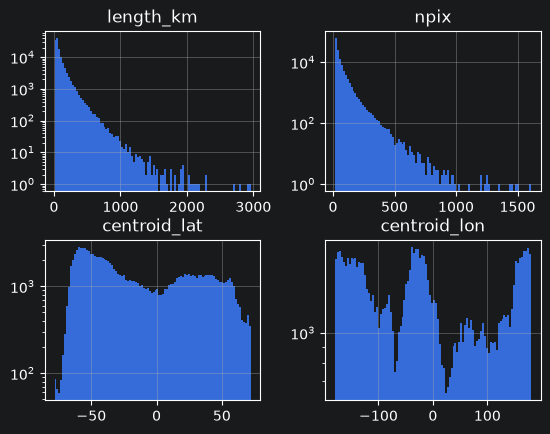

In [62]:
long_fronts.hist(bins=100, log=True)

In [50]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

PROJ = ccrs.PlateCarree()
EARTH_R = 6371.0


def plot_front_density(df, bin_deg=2.0, ax=None, cmap="magma", log=True):
    """Fronts per million km^2, binned on a regular lon/lat grid.

    A lon/lat cell shrinks toward the poles -- 2x2 degrees at 70N is about a
    third the area of the same cell at the equator -- so raw counts understate
    polar density and overstate tropical density.  Each cell is divided by its
    own area on the sphere, R^2 * dlon * (sin lat2 - sin lat1).
    """
    lon = df["centroid_lon"].to_numpy()
    lat = df["centroid_lat"].to_numpy()
    xe = np.arange(-180, 180 + bin_deg, bin_deg)
    ye = np.arange(-90, 90 + bin_deg, bin_deg)
    counts, _, _ = np.histogram2d(lon, lat, bins=[xe, ye])
    band = EARTH_R ** 2 * np.radians(bin_deg) * np.diff(np.sin(np.radians(ye)))
    density = counts / np.broadcast_to(band, counts.shape) * 1e6

    if ax is None:
        ax = plt.figure(figsize=(15, 7)).add_subplot(1, 1, 1, projection=PROJ)
    ax.set_global()
    ax.add_feature(cfeature.LAND, facecolor="0.92", zorder=0)
    ax.coastlines(linewidth=0.5, zorder=1)
    ax.gridlines(draw_labels=True, linewidth=0.3, alpha=0.5)

    # Empty cells are land or outside the model domain, not zero density.
    masked = np.ma.masked_where(counts.T == 0, density.T)
    pm = ax.pcolormesh(xe, ye, masked, cmap=cmap, transform=PROJ, zorder=2,
                       norm=LogNorm() if log else None)
    cb = ax.figure.colorbar(pm, ax=ax, shrink=0.75, pad=0.03)
    cb.set_label("fronts per million km$^2$")
    ax.set_title(f"{len(df):,} fronts, {bin_deg:g}$^\\circ$ bins", fontsize=10)
    return ax



<GeoAxes: title={'center': '163,212 fronts, 2$^\\circ$ bins'}>

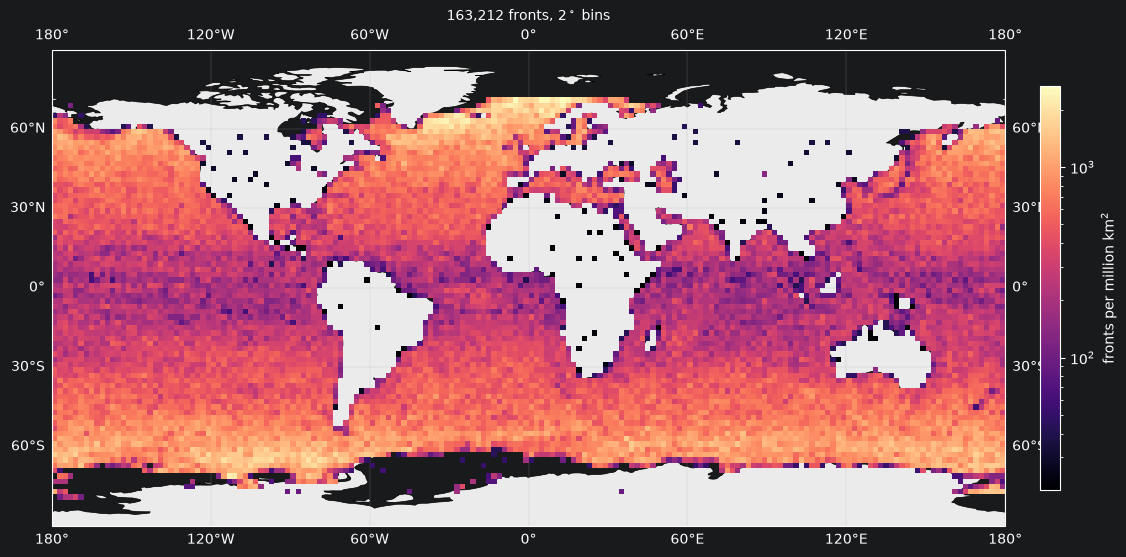

In [126]:
plot_front_density(fronts)


<GeoAxes: title={'center': '34,470 fronts, 2$^\\circ$ bins'}>

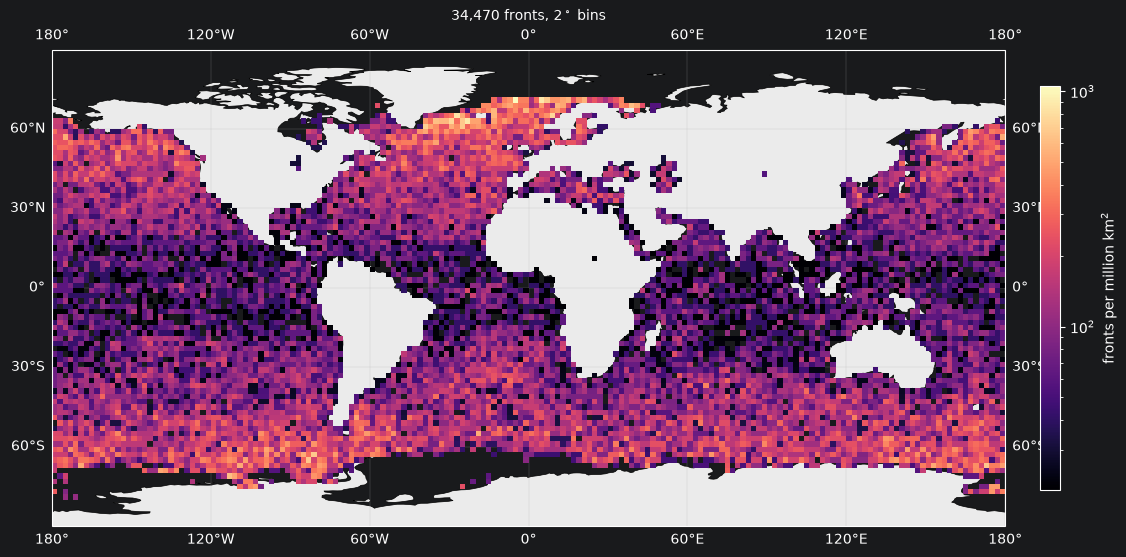

In [51]:
plot_front_density(short_fronts)

<GeoAxes: title={'center': '128,742 fronts, 2$^\\circ$ bins'}>

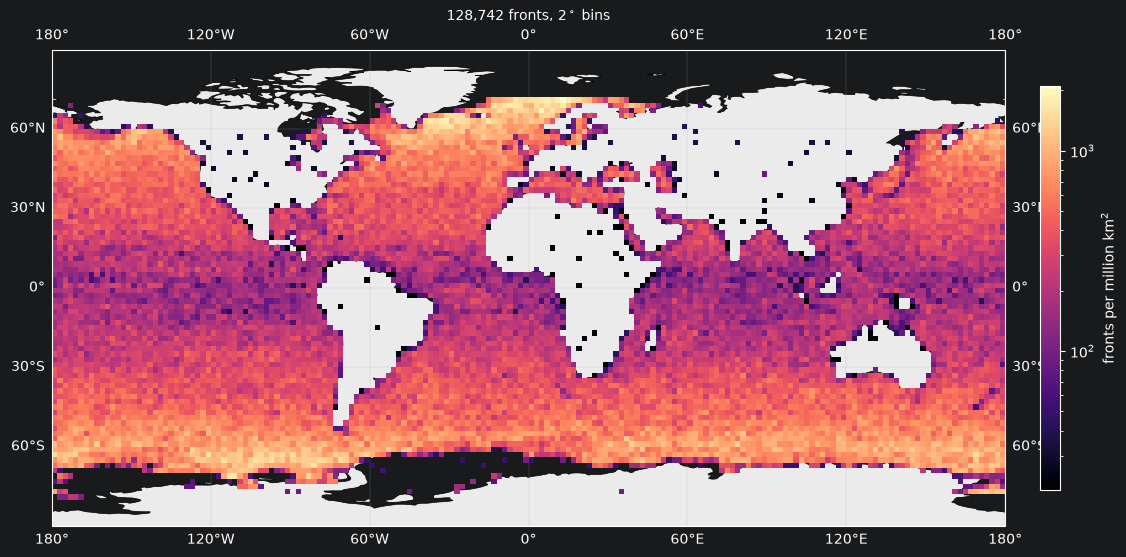

In [53]:
plot_front_density(long_fronts)

In [78]:
short_fronts_km = fronts[fronts["length_km"]< 20]

In [79]:
long_fronts_km = fronts[fronts["length_km"]>= 20]

15745


array([[<Axes: title={'center': 'length_km'}>,
        <Axes: title={'center': 'npix'}>],
       [<Axes: title={'center': 'centroid_lat'}>,
        <Axes: title={'center': 'centroid_lon'}>]], dtype=object)

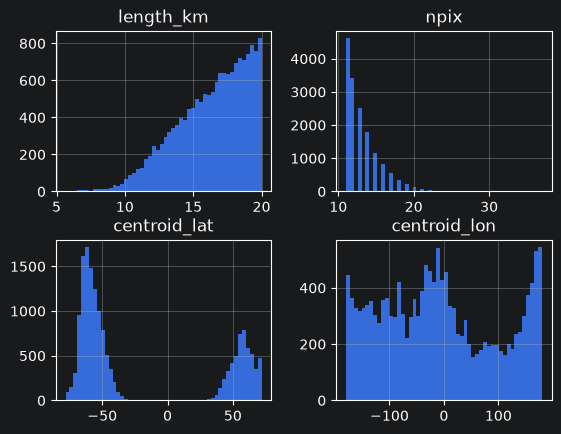

In [80]:
print(len(short_fronts_km))
short_fronts_km.hist(bins=50)

147467


array([[<Axes: title={'center': 'length_km'}>,
        <Axes: title={'center': 'npix'}>],
       [<Axes: title={'center': 'centroid_lat'}>,
        <Axes: title={'center': 'centroid_lon'}>]], dtype=object)

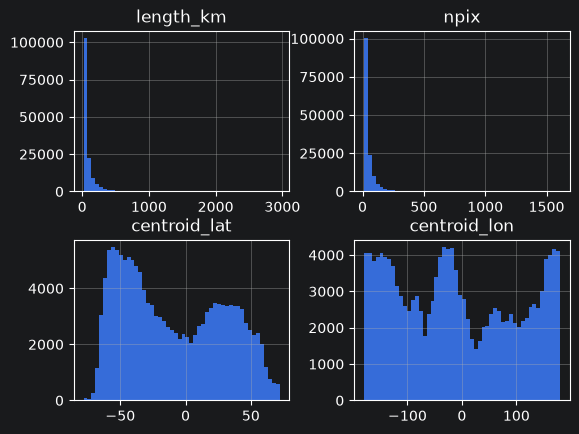

In [81]:
print(len(long_fronts_km))
long_fronts_km.hist(bins=50)

<GeoAxes: title={'center': '15,745 fronts, 2$^\\circ$ bins'}>

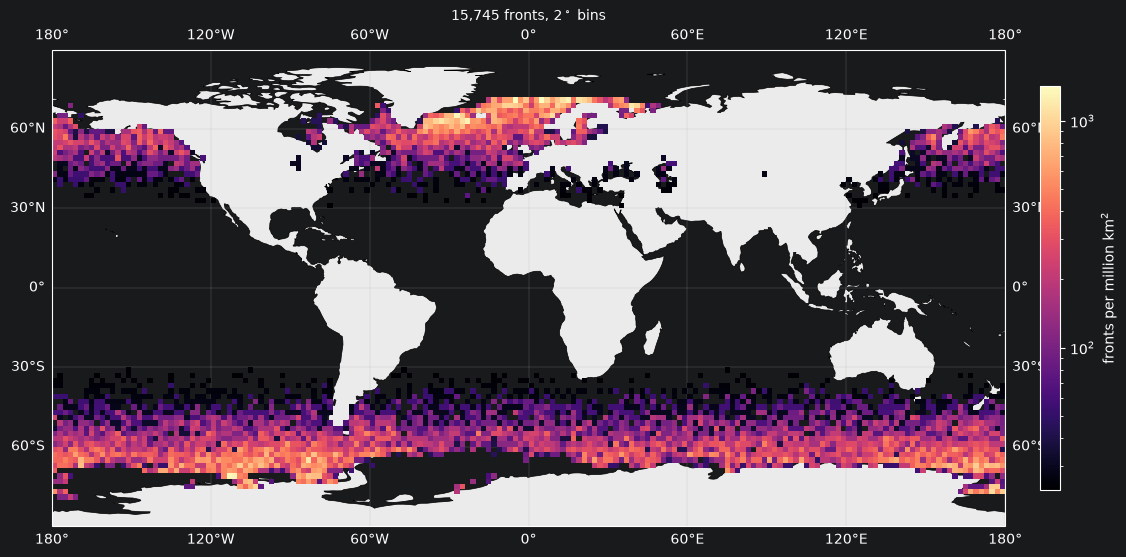

In [82]:
plot_front_density(short_fronts_km)

<GeoAxes: title={'center': '147,467 fronts, 2$^\\circ$ bins'}>

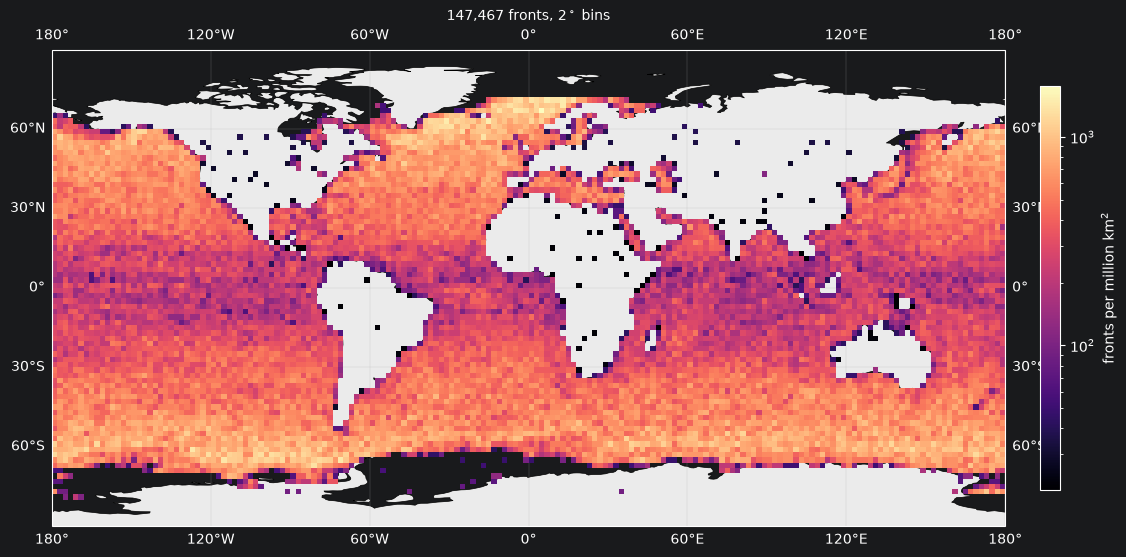

In [83]:
plot_front_density(long_fronts_km)

In [119]:
# embedding comparison


from nemi_sweep.sweep import run_sweep
from visualization.sweep_plots import (plot_all_metric_heatmaps,
                                       plot_embedding_grid)

FEATURES = ["num_branches", "mean_curvature", "orientation",
            "relative_vorticity", "turner_angle", "strain_n", "strain_s", "strain_mag", "divergence",
            "okubo_weiss",
            "gradtheta2", "gradsalt2", "gradb2", "gradeta2"]

ds_for_embedding = raw.select(FEATURES, stats=("mean", "std", "skew"), scaling="standardize", nan_policy="drop_rows", div_by_f=False, ihs_channels=True, log_channels=True, fill_value=0, missing_indicator=True)
ds_for_embedding.to_frame().head()

,date,label,name,time,num_branches,mean_curvature,orientation,relative_vorticity_mean,relative_vorticity_std,relative_vorticity_skew,...,gradtheta2_skew,gradsalt2_mean,gradsalt2_std,gradsalt2_skew,gradb2_mean,gradb2_std,gradb2_skew,gradeta2_mean,gradeta2_std,gradeta2_skew
0,20111204_000000,2455,20111204TT000000_72.9S_79.3W,2011-12-04T00:00:00,-0.313430,0.117785,0.781952,-0.240091,0.229543,-0.619423,...,0.602332,2.297659,2.380098,0.270265,2.900523,2.811272,0.371529,1.497059,1.886153,-0.025364
1,20111204_000000,2683,20111204TT000000_72.8S_73.7W,2011-12-04T00:00:00,-0.313430,1.201922,1.444877,-2.098738,0.861883,0.952197,...,-0.737148,2.412615,1.404074,-1.350147,2.909736,1.514178,-1.618553,2.768915,1.029753,-1.141265
2,20111204_000000,2717,20111204TT000000_72.8S_74.4W,2011-12-04T00:00:00,-0.313430,2.866091,-1.599951,-2.967209,1.096272,0.423809,...,0.028996,2.482553,1.850245,-0.557879,3.043629,2.083313,-0.744006,3.579275,2.629121,-1.150895
3,20111204_000000,2780,20111204TT000000_72.6S_75.0W,2011-12-04T00:00:00,0.868246,1.185931,1.312230,-3.003505,3.547134,-1.292402,...,0.519766,2.949929,3.016315,0.586494,3.657673,3.428814,0.898395,3.299769,3.040792,-0.575854
4,20111204_000000,10712,20111204TT000000_66.2S_92.7W,2011-12-04T00:00:00,-0.313430,-0.844386,1.048541,-2.228916,-0.161672,-0.072101,...,-0.827758,1.277141,1.016801,-1.305052,1.097481,0.809267,-1.363892,-0.973907,-0.944569,0.397804


In [120]:
ds_for_embedding.feature_names

['num_branches',
 'mean_curvature',
 'orientation',
 'relative_vorticity_mean',
 'relative_vorticity_std',
 'relative_vorticity_skew',
 'turner_angle_mean',
 'turner_angle_std',
 'turner_angle_skew',
 'strain_n_mean',
 'strain_n_std',
 'strain_n_skew',
 'strain_s_mean',
 'strain_s_std',
 'strain_s_skew',
 'strain_mag_mean',
 'strain_mag_std',
 'strain_mag_skew',
 'divergence_mean',
 'divergence_std',
 'divergence_skew',
 'okubo_weiss_mean',
 'okubo_weiss_std',
 'okubo_weiss_skew',
 'gradtheta2_mean',
 'gradtheta2_std',
 'gradtheta2_skew',
 'gradsalt2_mean',
 'gradsalt2_std',
 'gradsalt2_skew',
 'gradb2_mean',
 'gradb2_std',
 'gradb2_skew',
 'gradeta2_mean',
 'gradeta2_std',
 'gradeta2_skew']

In [121]:
EMBEDDING_GRID = {"n_neighbors": [40], "min_dist": [0.0]}


# CLUSTERING_GRID = {
#     "method": ["hdbscan"],
#     "min_cluster_size": [50, 100, 250, 500],
#     "min_samples": [5, 25, None],
# }
result = run_sweep(ds_for_embedding.X, EMBEDDING_GRID, #CLUSTERING_GRID,
                   n_components=2, device="cpu",
                   fit_size=None, metric_sample=5_000, keep_size=100_000)

embedding {'n_neighbors': 40, 'min_dist': 0.0}
   trustworthiness=0.825  continuity=0.917  normalized_stress=0.133


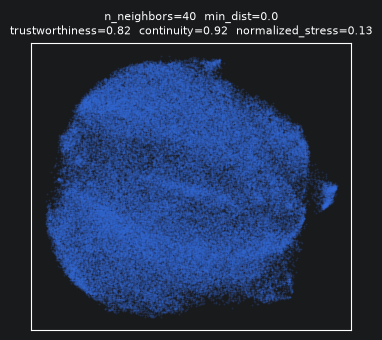

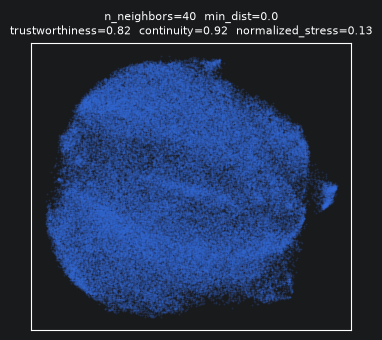

In [124]:
plot_embedding_grid(result, x="n_neighbors", y="min_dist", dims=2, alpha=0.2)

{} (100000, 2)


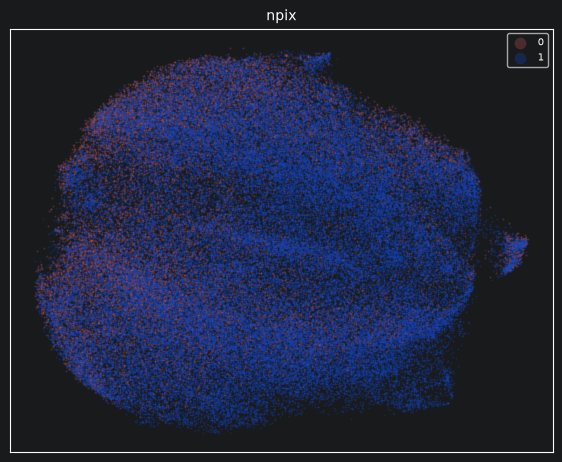

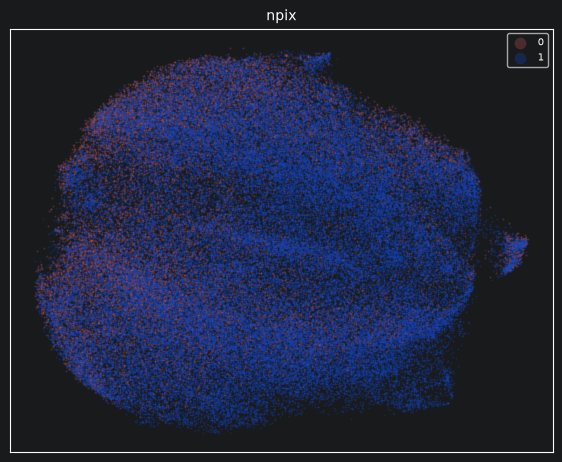

In [125]:
from visualization.embedding_plots import (plot_embedding_by,
                                           plot_embedding_features)

best = result.table["trustworthiness"].idxmax()
E = result.embeddings[best]
print(result.table.loc[best, list(result.swept)].to_dict(), E.shape)


# long_fronts_km = fronts[fronts["length_km"]>= 20]

meta = ds.meta(raw.table, ["centroid_lat", "centroid_lon", 'length_km', 'npix']).iloc[result.row_index]

plot_embedding_by(E, meta["npix"].to_numpy() > 15, dims=2, name="npix", alpha=0.3)